In [1]:
import random, json
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms

SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


In [2]:
import kagglehub
from pathlib import Path

path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")
cands = {d: sum(1 for c in d.iterdir() if c.is_dir()) for d in Path(path).rglob("*") if d.is_dir()}
color = [d for d in cands if d.name.lower() == "color" and cands[d] > 10]
DATA_DIR = str(color[0] if color else max(cands, key=cands.get))

base = datasets.ImageFolder(DATA_DIR)
classes = base.classes
labels = np.array(base.targets)
print(DATA_DIR); print(len(base), "images,", len(classes), "classes")

C:\Users\Ravinidi\.cache\kagglehub\datasets\abdallahalidev\plantvillage-dataset\versions\3\plantvillage dataset\color
54305 images, 38 classes


In [3]:
weights = models.MobileNet_V3_Small_Weights.DEFAULT
SIZE = 128
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

preprocess = transforms.Compose([transforms.Resize((SIZE, SIZE)), transforms.ToTensor(), norm])
aug_tf = transforms.Compose([
    transforms.Resize((SIZE, SIZE)), transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20), transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(), norm])

idx = np.arange(len(base))
tr, tmp = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
va, te = train_test_split(tmp, test_size=0.50, stratify=labels[tmp], random_state=SEED)
tr, _ = train_test_split(tr, train_size=0.25, stratify=labels[tr], random_state=SEED)  # 25% for speed

def make_loaders(augment=False, batch_size=32):
    train_ds = Subset(datasets.ImageFolder(DATA_DIR, transform=aug_tf if augment else preprocess), tr)
    val_ds   = Subset(datasets.ImageFolder(DATA_DIR, transform=preprocess), va)
    test_ds  = Subset(datasets.ImageFolder(DATA_DIR, transform=preprocess), te)
    return (DataLoader(train_ds, batch_size, shuffle=True, num_workers=0),
            DataLoader(val_ds, batch_size, num_workers=0),
            DataLoader(test_ds, batch_size, num_workers=0))

print(len(tr), "train |", len(va), "val |", len(te), "test")

9503 train | 8146 val | 8146 test


In [4]:
def build_model(freeze_backbone):
    m = models.mobilenet_v3_small(weights=weights)
    if freeze_backbone:
        for p in m.parameters():
            p.requires_grad = False
    m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, len(classes))
    return m.to(device)

def run_epoch(model, loader, loss_fn, optimizer=None):
    train = optimizer is not None
    model.train(train)
    tot, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x); loss = loss_fn(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            tot += loss.item() * len(y); correct += (out.argmax(1) == y).sum().item(); n += len(y)
    return tot / n, correct / n

def train_model(name, freeze, epochs, lr, augment):
    set_seed(SEED)
    model = build_model(freeze)
    train_dl, val_dl, _ = make_loaders(augment)
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
    best, hist = 0.0, []
    for e in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_dl, loss_fn, opt)
        vl, vacc = run_epoch(model, val_dl, loss_fn)
        hist.append((tl, ta, vl, vacc))
        print(f"[{name}] epoch {e}: train acc {ta:.3f} | val acc {vacc:.3f}")
        if vacc > best:
            best = vacc; torch.save(model.state_dict(), f"{name}.pt")
    model.load_state_dict(torch.load(f"{name}.pt", map_location=device))
    return model, hist

def evaluate(model):
    _, _, test_dl = make_loaders()
    model.eval(); preds, trues = [], []
    with torch.no_grad():
        for x, y in test_dl:
            preds += model(x.to(device)).argmax(1).cpu().tolist(); trues += y.tolist()
    rep = classification_report(trues, preds, output_dict=True, zero_division=0)
    return np.array(trues), np.array(preds), rep

In [5]:
results = {}
m_base, h_base = train_model("baseline", freeze=True, epochs=2, lr=1e-3, augment=False)
t, p, rep = evaluate(m_base)
results["Frozen baseline"] = (rep["accuracy"], rep["macro avg"]["f1-score"])
print(results)
json.dump(results, open("results.json", "w"))

[baseline] epoch 1: train acc 0.683 | val acc 0.836
[baseline] epoch 2: train acc 0.843 | val acc 0.858
{'Frozen baseline': (0.8574760618708569, 0.8177106340006991)}


In [7]:
m_ft, h_ft = train_model("finetune", freeze=False, epochs=2, lr=1e-4, augment=False)
t, p, rep = evaluate(m_ft)
results["Fine-tuned"] = (rep["accuracy"], rep["macro avg"]["f1-score"])
print(results)
json.dump(results, open("results.json", "w"))

[finetune] epoch 1: train acc 0.601 | val acc 0.865
[finetune] epoch 2: train acc 0.895 | val acc 0.930
{'Frozen baseline': (0.8574760618708569, 0.8177106340006991), 'Fine-tuned': (0.9332187576724773, 0.9084730719655448)}


In [8]:
m_aug, h_aug = train_model("finetune_aug", freeze=False, epochs=2, lr=1e-4, augment=True)
t, p, rep = evaluate(m_aug)
results["Fine-tuned + augmentation"] = (rep["accuracy"], rep["macro avg"]["f1-score"])
for k, (a, f) in results.items():
    print(f"{k:28s} test acc {a:.4f} | macro-F1 {f:.4f}")
json.dump(results, open("results.json", "w"))

[finetune_aug] epoch 1: train acc 0.576 | val acc 0.851
[finetune_aug] epoch 2: train acc 0.868 | val acc 0.926
Frozen baseline              test acc 0.8575 | macro-F1 0.8177
Fine-tuned                   test acc 0.9332 | macro-F1 0.9085
Fine-tuned + augmentation    test acc 0.9293 | macro-F1 0.9016


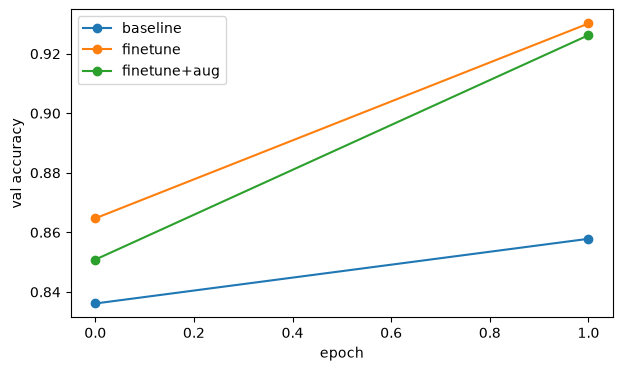

In [9]:
plt.figure(figsize=(7, 4))
for name, h in [("baseline", h_base), ("finetune", h_ft), ("finetune+aug", h_aug)]:
    plt.plot([x[3] for x in h], marker="o", label=name)
plt.xlabel("epoch"); plt.ylabel("val accuracy"); plt.legend(); plt.show()

544 errors out of 8146


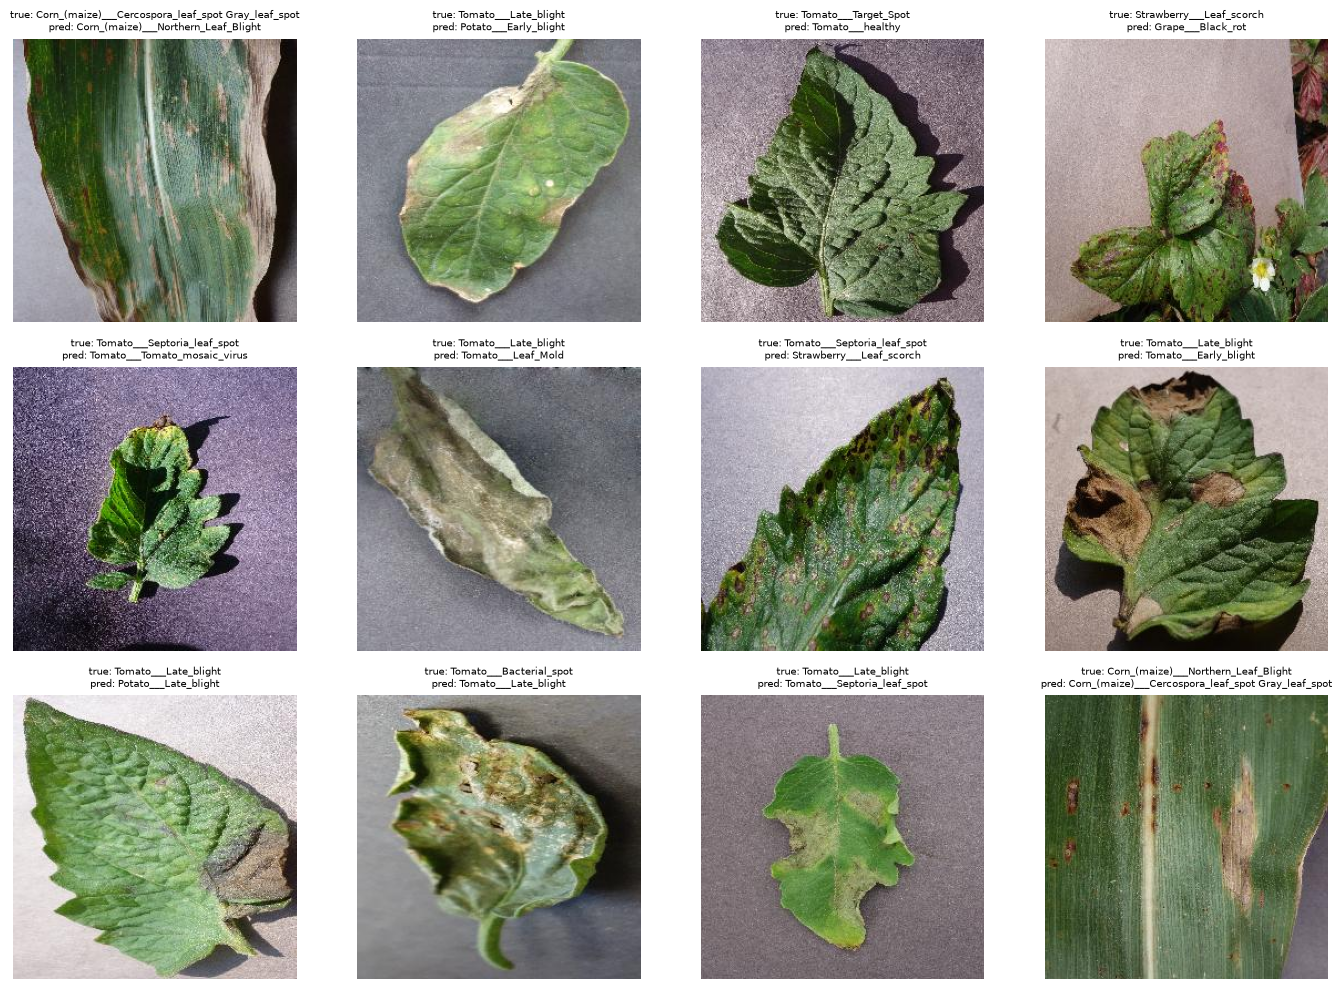

In [10]:
model = m_ft   # change to your best model
t, p, rep = evaluate(model)
wrong = [i for i in range(len(t)) if t[i] != p[i]]
print(len(wrong), "errors out of", len(t))

paths = [base.samples[i][0] for i in te]
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, w in zip(axes.ravel(), wrong[:12]):
    ax.imshow(Image.open(paths[w]).convert("RGB")); ax.axis("off")
    ax.set_title(f"true: {classes[t[w]]}\npred: {classes[p[w]]}", fontsize=7)
plt.tight_layout(); plt.show()

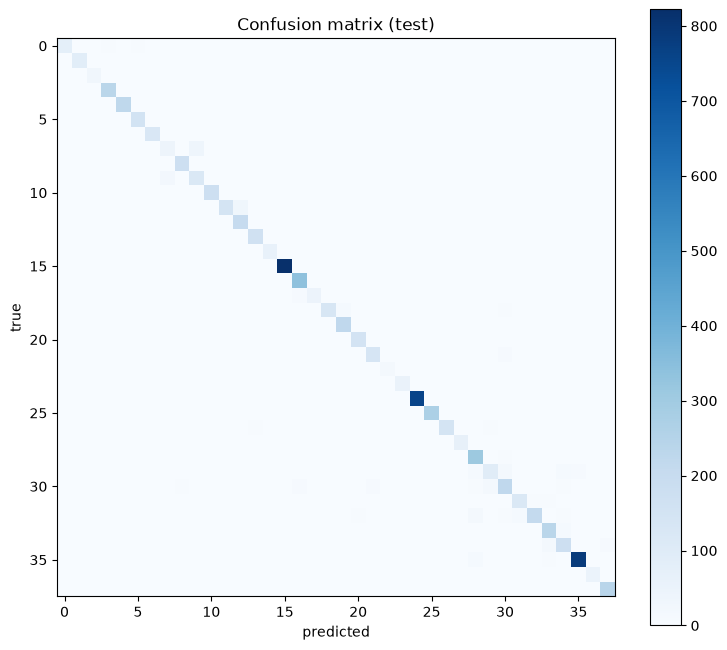

Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot F1 0.565
Tomato___Early_blight                         F1 0.683
Corn_(maize)___Northern_Leaf_Blight           F1 0.795
Tomato___Late_blight                          F1 0.796
Apple___Cedar_apple_rust                      F1 0.800


In [11]:
cm = confusion_matrix(t, p)
plt.figure(figsize=(9, 8)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.title("Confusion matrix (test)"); plt.xlabel("predicted"); plt.ylabel("true"); plt.show()

per_class = {classes[i]: rep[str(i)]["f1-score"] for i in range(len(classes)) if str(i) in rep}
for k, v in sorted(per_class.items(), key=lambda kv: kv[1])[:5]:
    print(f"{k:45s} F1 {v:.3f}")